# 24_CLAHE_SelfImpl: tự cài đặt CLAHE và đối chiếu với cv2.createCLAHE (feedback mục 2, R3)
Mục đích: có phần cài đặt riêng (NumPy, không gọi hàm CLAHE của thư viện), đối chiếu với OpenCV trên cùng ảnh và tham số, báo cáo sai khác đầu ra và thời gian chạy. Chạy lại được.

**Pseudocode** (ảnh xám G cỡ HxW, ngưỡng cắt c, lưới n x n; trong pipeline áp dụng lên kênh L của ảnh LAB)
1. Nếu H hoặc W không chia hết cho n: đệm dưới/phải bằng phản xạ cho chia hết. th, tw là cỡ một ô, N = th * tw.
2. Mỗi ô: hist[0..255] = số điểm ảnh theo giá trị xám.
3. lim = max(floor(c * N / 256), 1). E = tổng max(hist[i] - lim, 0). hist[i] = min(hist[i], lim). Mỗi bin cộng floor(E / 256). r = E mod 256: cộng thêm 1 vào r bin cách nhau max(floor(256 / r), 1), bắt đầu từ bin 0.
4. LUT[i] = làm tròn(255 / N * tổng hist[0..i]).
5. Mỗi điểm (y, x): u = y / th - 0.5, v = x / tw - 0.5 (tâm ô là điểm neo). Lấy 4 ô gần nhất (chặn ở biên), kết quả = nội suy song tuyến của 4 giá trị LUT[ô][G(y, x)].

In [1]:
#cell 1: cấu hình và CLAHE tự cài (NumPy). Không dùng hàm CLAHE của thư viện; cv2 chỉ dùng ở cell sau để đối chiếu
import cv2, numpy as np, pandas as pd, time
import matplotlib.pyplot as plt
from pathlib import Path

BASE = Path(r"C:\Users\Acer Nitro 5 Tiger\Downloads\Data_321")
OUT = BASE / "preprocess_demo"; OUT.mkdir(exist_ok=True)
exts = {".mp4", ".mov", ".avi", ".mkv"}

def clahe_self(gray, clip=2.0, tile=8):
    # CLAHE tự cài (ảnh xám uint8, lưới tile x tile), cùng quy ước với cv2.createCLAHE
    H, W = gray.shape; ty_n = tx_n = tile
    if H % ty_n or W % tx_n:                                   # ảnh không chia hết: đệm dưới/phải bằng phản xạ (reflect101)
        ext = np.pad(gray, ((0, ty_n - H % ty_n if H % ty_n else 0), (0, tx_n - W % tx_n if W % tx_n else 0)), mode="reflect")
    else:
        ext = gray
    th, tw = ext.shape[0] // ty_n, ext.shape[1] // tx_n         # kích thước 1 ô
    total = th * tw
    # 1) histogram 256 bin của từng ô
    tid = (np.arange(ext.shape[0]) // th)[:, None] * tx_n + (np.arange(ext.shape[1]) // tw)[None, :]
    hist = np.bincount((tid * 256 + ext).ravel(), minlength=ty_n * tx_n * 256).reshape(-1, 256).astype(np.int64)
    # 2) cắt histogram ở ngưỡng, chia đều phần bị cắt cho 256 bin, phần dư rải cách đều
    lim = max(int(clip * total / 256), 1) if clip > 0 else 2**31 - 1
    clipped = np.maximum(hist - lim, 0).sum(1); hist = np.minimum(hist, lim)
    batch = clipped // 256; resid = clipped - batch * 256; hist += batch[:, None]
    for t in np.nonzero(resid)[0]:
        step = max(256 // int(resid[t]), 1)
        hist[t, np.arange(0, 256, step)[:int(resid[t])]] += 1
    # 3) hàm phân phối tích lũy -> bảng tra LUT từng ô (thang 0..255)
    scale = np.float32(255.0 / total)
    lut = np.clip(np.rint(np.cumsum(hist, 1).astype(np.float32) * scale), 0, 255).astype(np.float32).reshape(ty_n, tx_n, 256)
    # 4) nội suy song tuyến giữa 4 ô gần nhất cho từng điểm ảnh (tâm ô là điểm neo), tránh viền giữa các ô
    fy = np.arange(H, dtype=np.float32) * np.float32(1.0 / th) - np.float32(0.5)
    fx = np.arange(W, dtype=np.float32) * np.float32(1.0 / tw) - np.float32(0.5)
    y1 = np.floor(fy).astype(np.int64); x1 = np.floor(fx).astype(np.int64)
    ya = (fy - y1).astype(np.float32)[:, None]; xa = (fx - x1).astype(np.float32)[None, :]
    y1c = np.maximum(y1, 0)[:, None]; y2c = np.minimum(y1 + 1, ty_n - 1)[:, None]
    x1c = np.maximum(x1, 0)[None, :]; x2c = np.minimum(x1 + 1, tx_n - 1)[None, :]
    g = gray
    top = lut[y1c, x1c, g] * (1 - xa) + lut[y1c, x2c, g] * xa
    bot = lut[y2c, x1c, g] * (1 - xa) + lut[y2c, x2c, g] * xa
    return np.clip(np.rint(top * (1 - ya) + bot * ya), 0, 255).astype(np.uint8)

print("Đã định nghĩa clahe_self | OpenCV:", cv2.__version__)

Đã định nghĩa clahe_self | OpenCV: 5.0.0


In [2]:
#cell 2: đối chiếu trên ảnh tổng hợp (có điểm sáng, gradient, nhiễu): nhiều cỡ ảnh (có cỡ không chia hết cho lưới) và tham số
rng = np.random.default_rng(1)
def synth(h, w):
    y, x = np.mgrid[0:h, 0:w]
    im = 80 + 60 * np.sin(x / 37) + 40 * np.cos(y / 23) + rng.normal(0, 8, (h, w))
    im[h // 4:h // 2, w // 3:w // 2] = 200
    return np.clip(im, 0, 255).astype(np.uint8)

def so_sanh(g, clip, tile, n=5):
    ref = cv2.createCLAHE(clipLimit=clip, tileGridSize=(tile, tile)).apply(g); out = clahe_self(g, clip, tile)
    d = np.abs(out.astype(int) - ref.astype(int))
    def tg(f):
        ts = []
        for _ in range(n):
            t = time.perf_counter(); f(); ts.append((time.perf_counter() - t) * 1000)
        return round(float(np.median(ts)), 2)
    return dict(bang_nhau_pct=round(100 * (d == 0).mean(), 4), max_lech=int(d.max()), lech_tb=round(float(d.mean()), 5),
                ms_tu_cai=tg(lambda: clahe_self(g, clip, tile)), ms_cv2=tg(lambda: cv2.createCLAHE(clipLimit=clip, tileGridSize=(tile, tile)).apply(g)))

rows = []
for (h, w) in [(256, 256), (480, 640), (250, 333), (1080, 1920)]:
    g = synth(h, w)
    for clip, tile in [(2.0, 8), (4.0, 8), (2.0, 4), (40.0, 8)]:
        rows.append(dict(anh="tong_hop", kich_thuoc=f"{h}x{w}", clip=clip, luoi=tile, **so_sanh(g, clip, tile)))
t1 = pd.DataFrame(rows); print(t1.to_string(index=False))

     anh kich_thuoc  clip  luoi  bang_nhau_pct  max_lech  lech_tb  ms_tu_cai  ms_cv2
tong_hop    256x256   2.0     8          100.0         0      0.0       1.57    0.07
tong_hop    256x256   4.0     8          100.0         0      0.0       1.73    0.06
tong_hop    256x256   2.0     4          100.0         0      0.0       2.35    0.08
tong_hop    256x256  40.0     8          100.0         0      0.0       1.61    0.07
tong_hop    480x640   2.0     8          100.0         0      0.0      12.56    0.14
tong_hop    480x640   4.0     8          100.0         0      0.0      10.92    0.19
tong_hop    480x640   2.0     4          100.0         0      0.0      10.14    0.12
tong_hop    480x640  40.0     8          100.0         0      0.0      10.66    0.14
tong_hop    250x333   2.0     8          100.0         0      0.0       2.16    0.06
tong_hop    250x333   4.0     8          100.0         0      0.0       1.85    0.06
tong_hop    250x333   2.0     4          100.0         0      0.0

            anh               kich_thuoc  clip  luoi  bang_nhau_pct  max_lech  lech_tb  ms_tu_cai  ms_cv2
   Dataset_hand 1080x1920 (khung day du)   2.0     8          100.0         0      0.0      78.20    3.49
   Dataset_hand        256x256 (256x256)   2.0     8          100.0         0      0.0       1.73    0.07
dataset_labeled 1080x1920 (khung day du)   2.0     8          100.0         0      0.0      73.06    2.04
dataset_labeled        256x256 (256x256)   2.0     8          100.0         0      0.0       1.43    0.05
  Dataset_bonus 1080x1920 (khung day du)   2.0     8          100.0         0      0.0      72.61    2.16
  Dataset_bonus        256x256 (256x256)   2.0     8          100.0         0      0.0       1.68    0.04


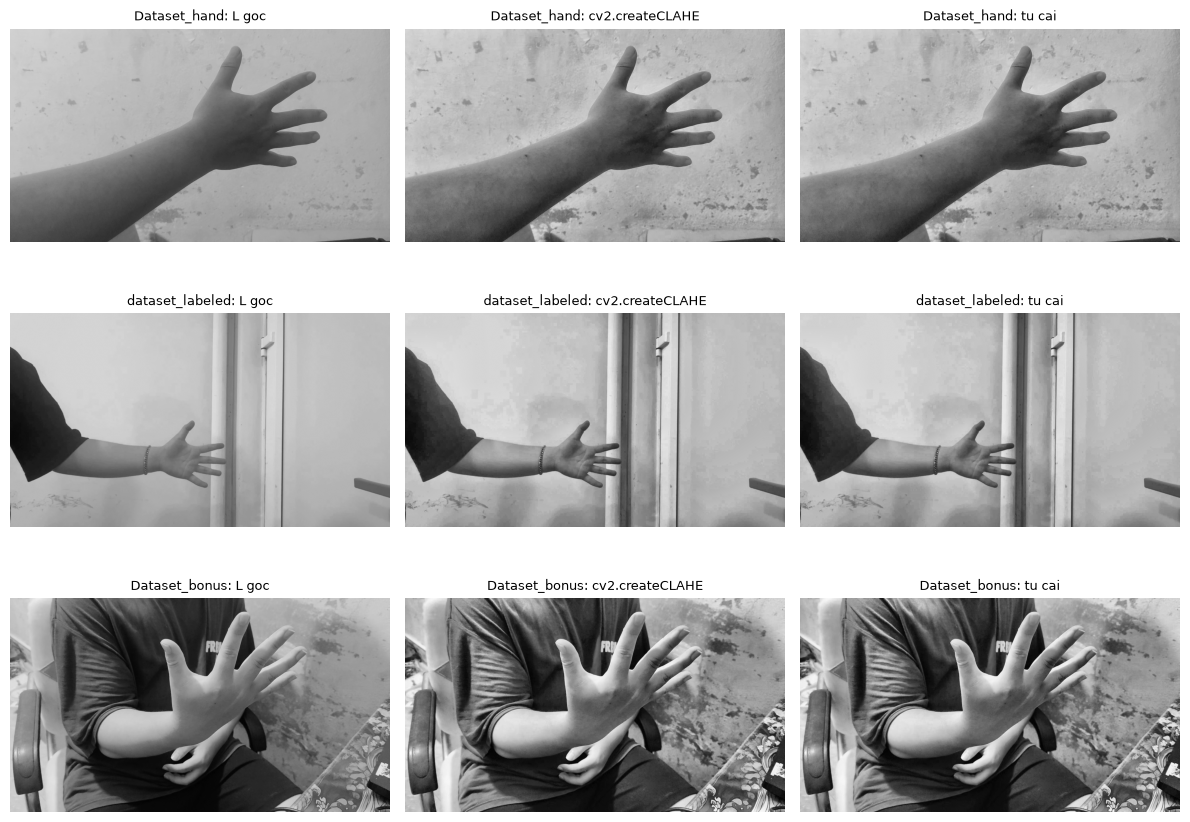

Đã lưu: C:\Users\Acer Nitro 5 Tiger\Downloads\Data_321\preprocess_demo\clahe_selfimpl.csv và C:\Users\Acer Nitro 5 Tiger\Downloads\Data_321\preprocess_demo\clahe_selfimpl.png


In [3]:
#cell 3: đối chiếu trên khung thật (kênh L của ảnh LAB) của 3 nguồn: khung đầy đủ và bản thu nhỏ 256x256, tham số của pipeline (clip 2,0, lưới 8). Lưu bảng CSV và hình
rows, fig = [], plt.figure(figsize=(12, 9))
for i, src in enumerate(["Dataset_hand", "dataset_labeled", "Dataset_bonus"]):
    p = next(q for q in sorted((BASE / src).rglob("*")) if q.suffix.lower() in exts)
    cap = cv2.VideoCapture(str(p)); cap.set(cv2.CAP_PROP_POS_FRAMES, int(cap.get(cv2.CAP_PROP_FRAME_COUNT)) // 2)
    ok, fr = cap.read(); cap.release(); assert ok, p
    L = cv2.cvtColor(fr, cv2.COLOR_BGR2LAB)[:, :, 0]
    for tenh, g in [("khung day du", L), ("256x256", cv2.resize(L, (256, 256), interpolation=cv2.INTER_AREA))]:
        rows.append(dict(anh=src, kich_thuoc=f"{g.shape[0]}x{g.shape[1]} ({tenh})", clip=2.0, luoi=8, **so_sanh(g, 2.0, 8, n=10)))
    ref = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(L); out = clahe_self(L, 2.0, 8)
    for j, (im, t) in enumerate([(L, "L goc"), (ref, "cv2.createCLAHE"), (out, "tu cai")]):
        ax = fig.add_subplot(3, 3, i * 3 + j + 1); ax.imshow(im, cmap="gray", vmin=0, vmax=255); ax.set_title(f"{src}: {t}", fontsize=9); ax.axis("off")
t2 = pd.DataFrame(rows); print(t2.to_string(index=False))
plt.tight_layout(); plt.savefig(OUT / "clahe_selfimpl.png", dpi=80); plt.show()
pd.concat([t1, t2]).to_csv(OUT / "clahe_selfimpl.csv", index=False)
print("Đã lưu:", OUT / "clahe_selfimpl.csv", "và", OUT / "clahe_selfimpl.png")